In [1]:
import os
import sys

import torch
from torchvision import transforms
import shutil
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

sys.path.append("../scripts")

from SAM2_utils import load_sam2_model, process_folder, save_overlay
from mask_classifier import process_mask_files, retrieve_right_masks
from CNN import SmallCNN

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA available: True
Device: NVIDIA GeForce RTX 3060 Laptop GPU


In [3]:
image_folder = "../data/test/Hypericum_perforatum/"

mask_output = "../output_masks/test/masks/"
overlay_output = "../output_masks/test/mask_overlays/"

os.makedirs(mask_output, exist_ok=True)
os.makedirs(overlay_output, exist_ok=True)

PATH_DIR = "../output_masks/test"
MASK_DIR = os.path.join(PATH_DIR, "masks")
CROP_OUTPUT = os.path.join(PATH_DIR, "mask_crops")

TEST_DIR = "../data/CNN_dataset/test/"
os.makedirs(TEST_DIR, exist_ok=True)

In [4]:
checkpoint = "/mnt/c/Users/maner/git/projet-de-recherche-etude-de-biodiversite/segment-anything-2/checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

mask_generator = load_sam2_model(checkpoint, model_cfg, device=device)

In [5]:
process_folder(
    image_folder,
    mask_generator,
    mask_output,
    overlay_output,
    linewidth=1.5
)

Processing Hypericum perforatum_334396970.jpg
Saved overlay → ../output_masks/test/mask_overlays/Hypericum perforatum_334396970_overlay.png
Processing Hypericum perforatum_334396984.jpg
Saved overlay → ../output_masks/test/mask_overlays/Hypericum perforatum_334396984_overlay.png
Processing Hypericum perforatum_335646605.jpg
Saved overlay → ../output_masks/test/mask_overlays/Hypericum perforatum_335646605_overlay.png
Processing Hypericum perforatum_336319938.jpg
Saved overlay → ../output_masks/test/mask_overlays/Hypericum perforatum_336319938_overlay.png
Processing Hypericum perforatum_336888605.jpg
Saved overlay → ../output_masks/test/mask_overlays/Hypericum perforatum_336888605_overlay.png


In [6]:
process_mask_files(
    image_folder,
    MASK_DIR,
    CROP_OUTPUT
)

../data/test/Hypericum_perforatum/Hypericum perforatum_334396970.jpg
20 crops saved to ../output_masks/test/mask_crops/Hypericum perforatum_334396970
../data/test/Hypericum_perforatum/Hypericum perforatum_334396984.jpg
6 crops saved to ../output_masks/test/mask_crops/Hypericum perforatum_334396984
../data/test/Hypericum_perforatum/Hypericum perforatum_335646605.jpg
18 crops saved to ../output_masks/test/mask_crops/Hypericum perforatum_335646605
../data/test/Hypericum_perforatum/Hypericum perforatum_336319938.jpg
22 crops saved to ../output_masks/test/mask_crops/Hypericum perforatum_336319938
../data/test/Hypericum_perforatum/Hypericum perforatum_336888605.jpg
34 crops saved to ../output_masks/test/mask_crops/Hypericum perforatum_336888605


In [7]:
for root, _ , files in os.walk(CROP_OUTPUT):
    for file in files:

        #Move the file to ../data/CNN_dataset/test/
        os.rename(os.path.join(root, file), os.path.join(TEST_DIR, file))

In [8]:
# Load model
model = SmallCNN()
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.Pad(25),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

# Run CNN on crops and save accepted ones to PATH_FLOWERS
PATH_FLOWERS = "../data/test/"
os.makedirs(PATH_FLOWERS, exist_ok=True)

for crop_file in os.listdir(TEST_DIR):

    crop_path = os.path.join(TEST_DIR, crop_file)

    img = Image.open(crop_path).convert("RGB")
    tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        if output.item() >= 0:
            predicted = 1 
        else:
            predicted = 0

    # Save accepted crops with naming convention: name_id_number.png
    if predicted == 0:
        shutil.copy(crop_path, os.path.join(PATH_FLOWERS, crop_file))

retrieve_right_masks(PATH_FLOWERS=PATH_FLOWERS, PATH_MASKS=PATH_DIR)

print("Done — filtered masks saved to ../output_masks/test/masks_filtered/")

Done — filtered masks saved to ../output_masks/test/masks_filtered/


In [9]:
DISPLAY_DIR = "../output_masks/test/filtered_masks_overlays/"
os.makedirs(DISPLAY_DIR, exist_ok=True)

# Load filtered masks per image
masks_filtered_dir = os.path.join(PATH_DIR, "masks_filtered")

for mask_file in os.listdir(masks_filtered_dir):
    if not mask_file.endswith(".npy"):
        continue

    # Load the corresponding original image
    image_name = mask_file.replace("_masks.npy", ".jpg")
    image_path = os.path.join(image_folder, image_name)
    image = np.array(Image.open(image_path).convert("RGB"))

    # Load the filtered masks for this image
    masks = np.load(os.path.join(masks_filtered_dir, mask_file), allow_pickle=True)

    # save overlay
    overlay_path = os.path.join(
        DISPLAY_DIR,
        f"{os.path.splitext(mask_file)[0].replace('_masks', '')}_overlay.png"  
    )

    save_overlay(image, masks, overlay_path, linewidth=1.5)

    print(f"Saved overlay → {overlay_path}")

Saved overlay → ../output_masks/test/filtered_masks_overlays/Hypericum perforatum_334396970_overlay.png
Saved overlay → ../output_masks/test/filtered_masks_overlays/Hypericum perforatum_334396984_overlay.png
Saved overlay → ../output_masks/test/filtered_masks_overlays/Hypericum perforatum_335646605_overlay.png
Saved overlay → ../output_masks/test/filtered_masks_overlays/Hypericum perforatum_336319938_overlay.png
Saved overlay → ../output_masks/test/filtered_masks_overlays/Hypericum perforatum_336888605_overlay.png


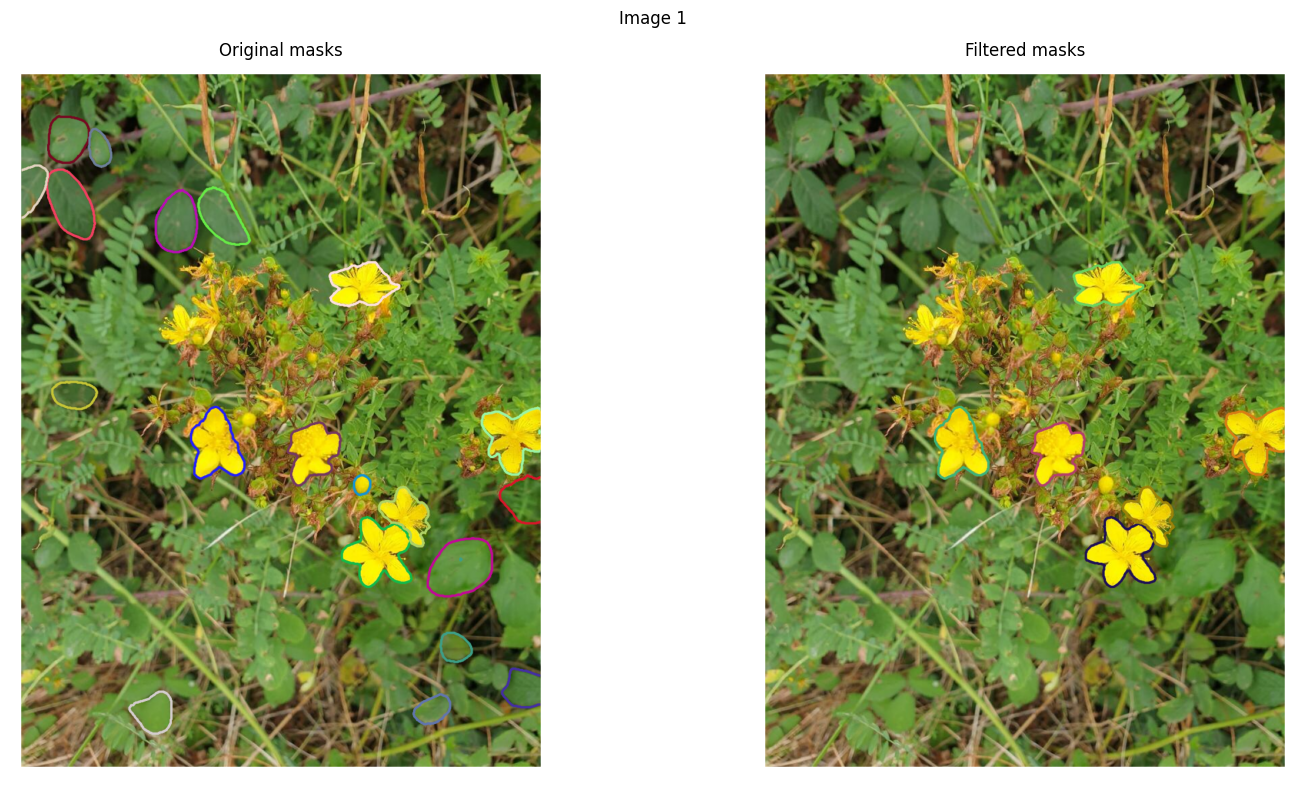

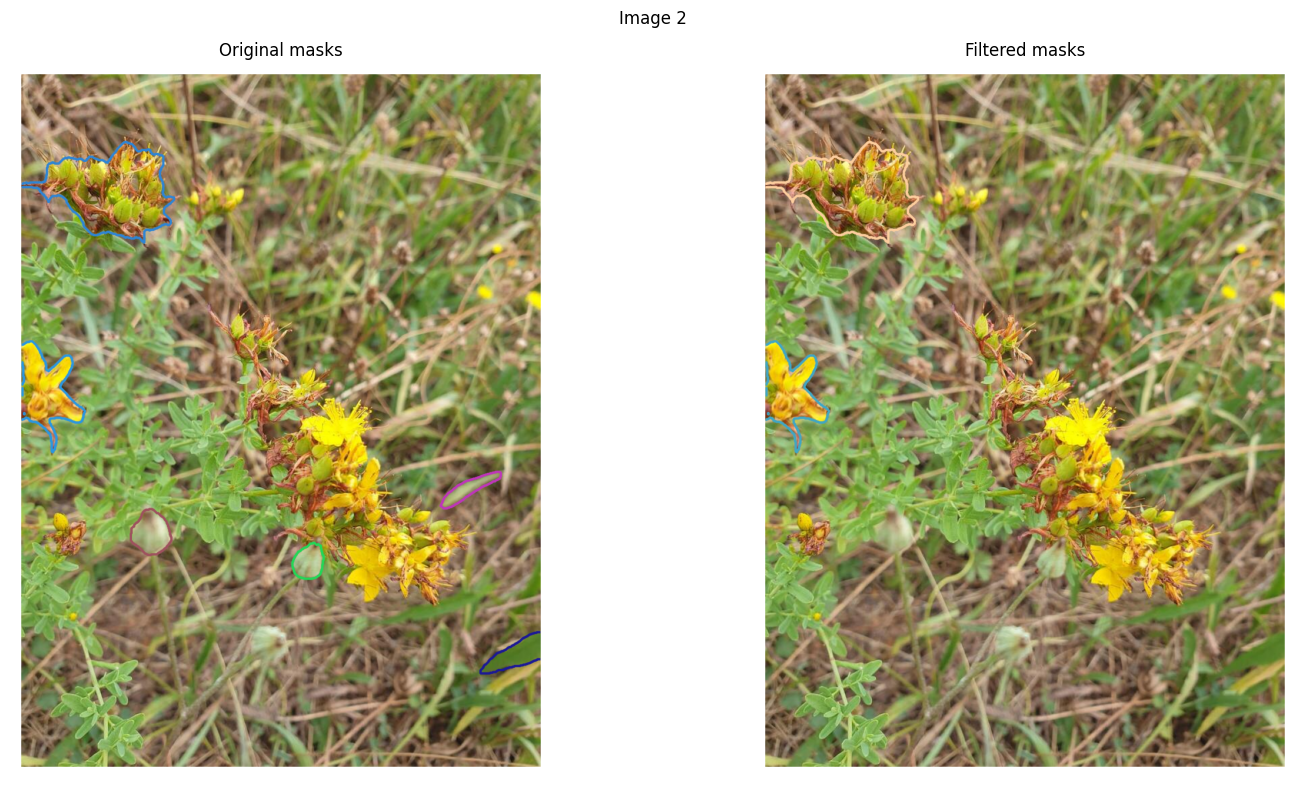

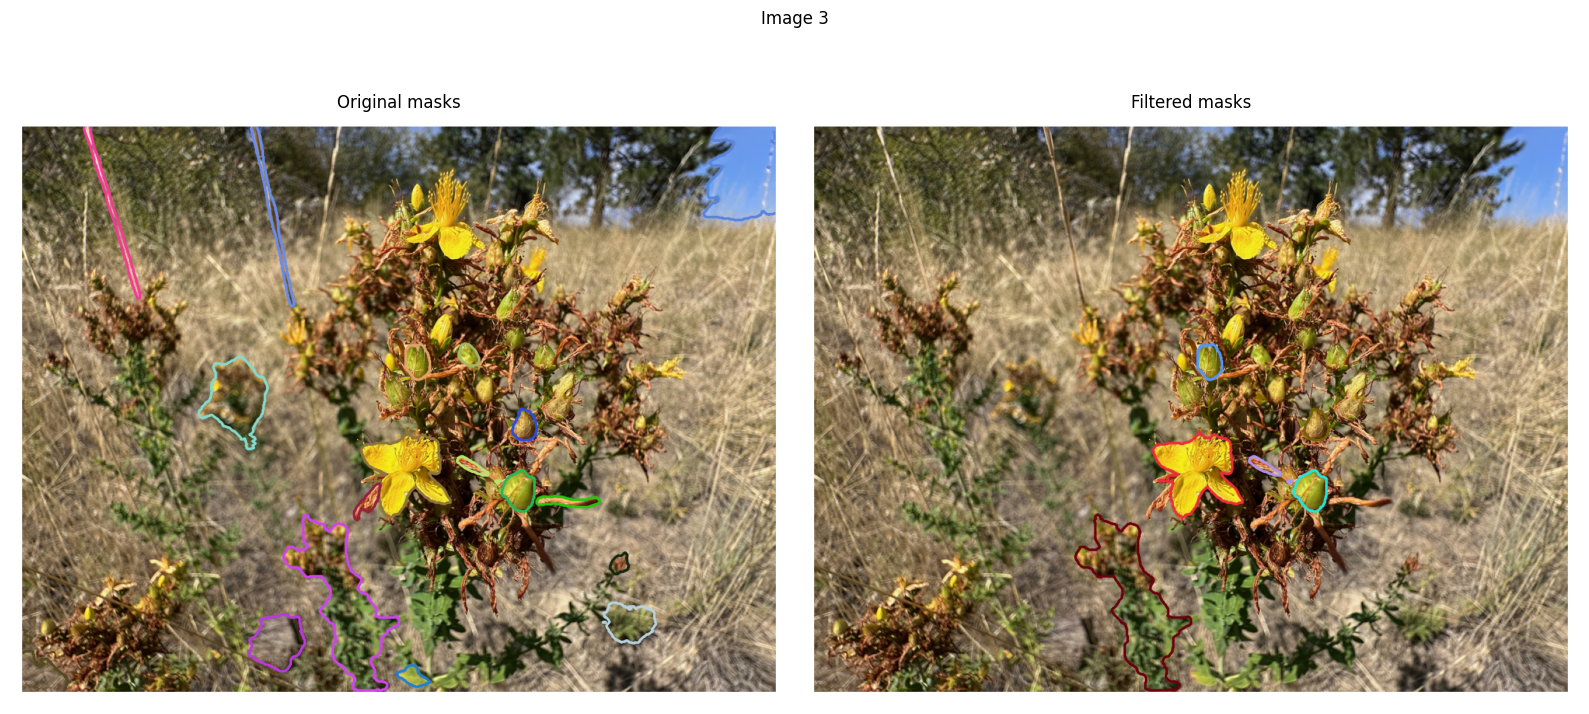

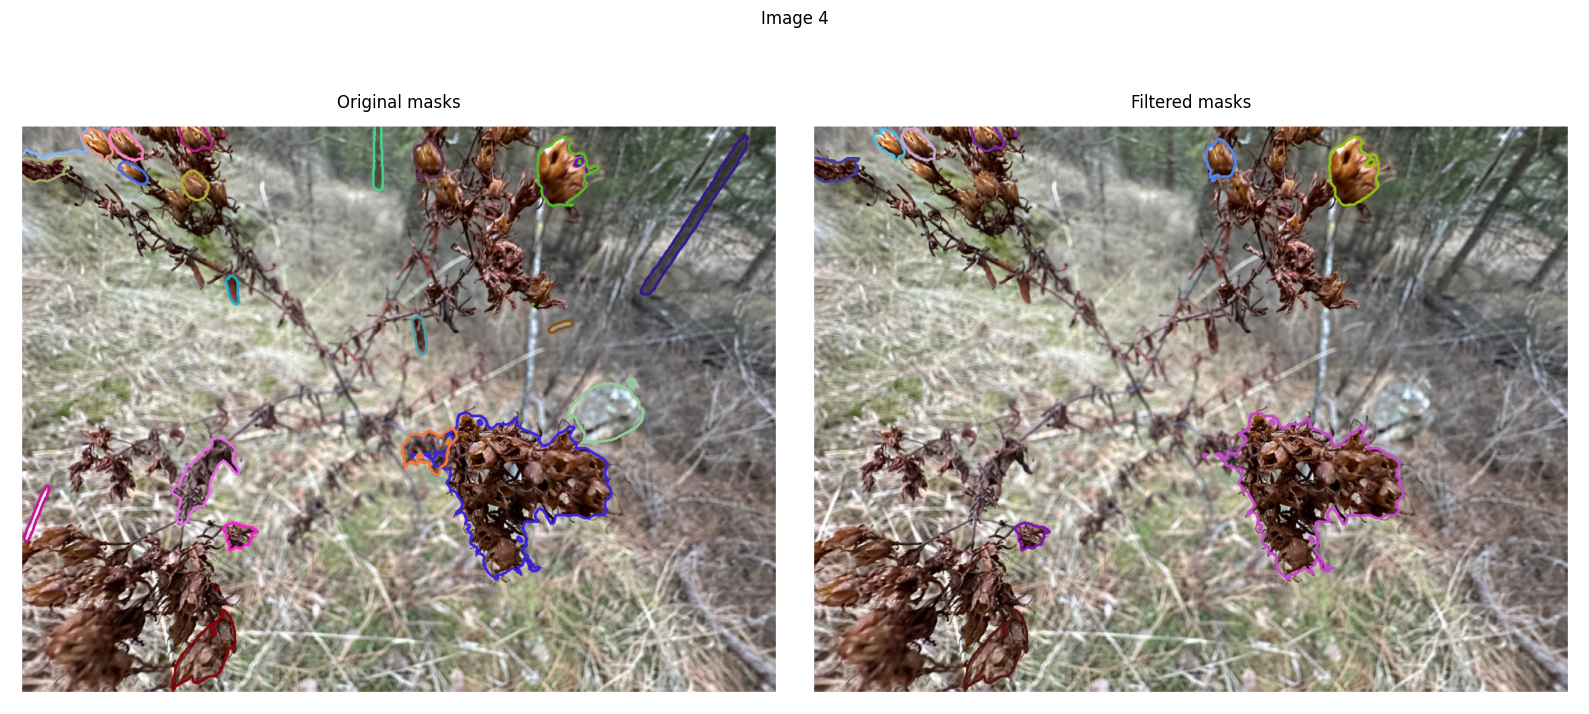

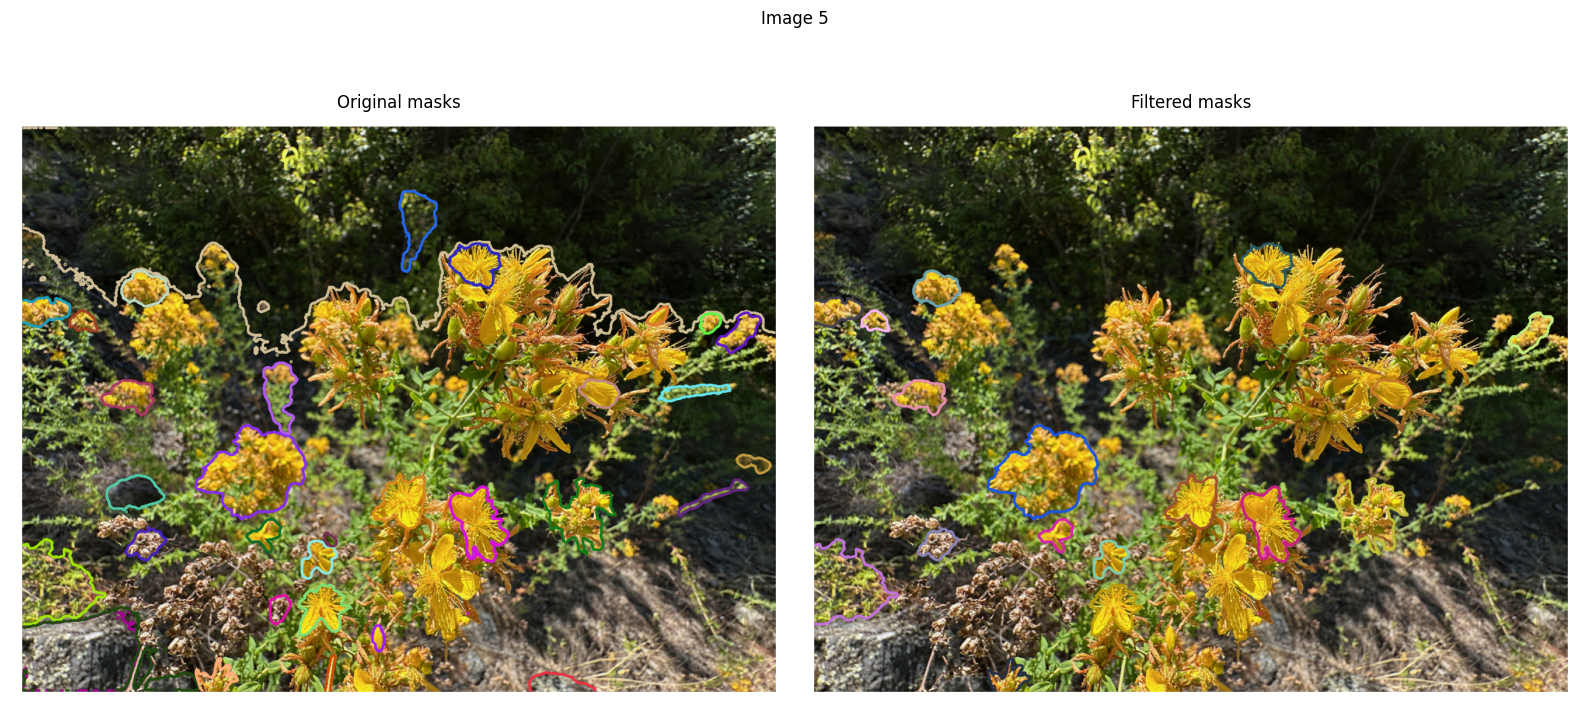

In [10]:
ORIGINAL_OVERLAY_DIR = "../output_masks/test/mask_overlays/"
count = 1

for image_name in os.listdir(DISPLAY_DIR):
    if not image_name.endswith(".png"):
        continue

    original_overlay_path = os.path.join(ORIGINAL_OVERLAY_DIR, image_name)
    filtered_overlay_path = os.path.join(DISPLAY_DIR, image_name)

    original_overlay = np.array(Image.open(original_overlay_path).convert("RGB"))
    filtered_overlay = np.array(Image.open(filtered_overlay_path).convert("RGB"))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    ax1.imshow(original_overlay)
    ax1.set_title("Original masks")
    ax1.axis("off")

    ax2.imshow(filtered_overlay)
    ax2.set_title("Filtered masks")
    ax2.axis("off")

    plt.suptitle(f"Image {count}")

    count+=1
    plt.tight_layout()
    plt.show()